# MLP TD-PINNs: Strong vs Weak Form — Sawtooth & Gaussian Shock

**PDE:**
$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}, \quad x\in[0,2\pi],\; t\in[0,T]$$

This notebook compares **TD-PINNs with MLP** under two loss forms:

| Form | Loss |
|---|---|
| **Strong** | $(1/N)\sum_i R(x_i)^2$ — pointwise MSE |
| **Weak** | $(1/K)\sum_k\left((1/N)\sum_i R(x_i)\,v_k(x_i)\right)^2$ — Petrov–Galerkin |

on two benchmarks:

- **Sawtooth** — Hopf–Cole analytic sawtooth ($\nu=0.07$), sharp viscous front  
- **Gaussian** — Gaussian hump ($\nu=0.05$) that steepens into a shock-like layer

Diagnostics reported: **L1, L2, L∞ errors** and **mass / energy conservation**.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.dirname(os.getcwd()))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.special import erf as sp_erf

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    collocation_curvature, compute_error,
)

try:
    _trapz = np.trapezoid   # NumPy >= 2.0
except AttributeError:
    _trapz = np.trapz

torch.manual_seed(42)
np.random.seed(42)
print('torch:', torch.__version__)
print('device:', 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))

torch: 2.10.0+cu128
device: cpu


/home/df.gomezb/.env/lib/python3.12/site-packages/torch/cuda/__init__.py:184: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


## 1. Exact Solutions

### Case A — Sawtooth (Hopf–Cole)

$$u(t,x)=2\nu\,\partial_x\ln\phi+4,\qquad\phi=e^{-a}+e^{-b}$$

$$a=\frac{(x-4t)^2}{4\nu(t+1)},\quad b=\frac{(x-4t-2\pi)^2}{4\nu(t+1)}$$

Sawtooth sharpens toward a viscous shock near $x=4t+\pi$.  With $\nu=0.07$ the shock is visible but well-resolved on $T=0.015$.

### Case B — Gaussian Shock (Hopf–Cole integral form)

$$u_0(x)=A\exp\!\left(-\frac{(x-x_0)^2}{2\sigma^2}\right)$$

The exact solution is obtained via the Hopf–Cole substitution $u=-2\nu\,\partial_x\ln\phi$, where $\phi$ solves the heat equation:

$$\phi(t,x)=\frac{1}{\sqrt{4\pi\nu t}}\int_{-\infty}^{\infty}\phi_0(y)\,e^{-(x-y)^2/(4\nu t)}\,dy,\qquad\phi_0(y)=\exp\!\left(-\frac{1}{2\nu}\int_0^y u_0(s)\,ds\right)$$

Differentiating analytically:

$$u(t,x)=\frac{\displaystyle\int\phi_0(y)\,\frac{x-y}{t}\,e^{-(x-y)^2/(4\nu t)}\,dy}{\displaystyle\int\phi_0(y)\,e^{-(x-y)^2/(4\nu t)}\,dy}$$

Both integrals are evaluated numerically (4 000-point trapezoid rule) on $[x_0-10\sigma,\,x_0+10\sigma]$.

In [2]:
# ── Sawtooth parameters ────────────────────────────────────────────────────────
NU_S  = 0.07
X0, XF = 0.0, 2 * np.pi
T_S, DT_S = 0.015, 0.005
NT_S = round(T_S / DT_S)   # 3 steps
TIMES_S = [k * DT_S for k in range(NT_S + 1)]

def hopf_cole(t, x, nu=NU_S):
    x = np.asarray(x, dtype=float)
    c = 4 * nu * (t + 1)
    a = (-4*t + x)**2 / c
    b = (-4*t + x - 2*np.pi)**2 / c
    num = ((-8*t + 2*x) * np.exp(-a) + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / c
    den = np.exp(-b) + np.exp(-a)
    return 2 * nu * num / den + 4

# ── Gaussian parameters ────────────────────────────────────────────────────────
NU_G   = 0.05
A_G    = 2.0
SIGMA_G = 0.5
X0_G   = np.pi
T_G, DT_G = 0.3, 0.1
NT_G = round(T_G / DT_G)   # 3 steps
TIMES_G = [k * DT_G for k in range(NT_G + 1)]

_sqrt2 = np.sqrt(2.0)
_erf_ref_G = sp_erf(-X0_G / (SIGMA_G * _sqrt2))

def gaussian_exact(t, x_arr, nu=NU_G, A=A_G, x0=X0_G, sigma=SIGMA_G):
    """Hopf-Cole exact solution for Gaussian IC via vectorized quadrature."""
    x_arr = np.asarray(x_arr, dtype=float)
    if t == 0:
        return A * np.exp(-(x_arr - x0)**2 / (2 * sigma**2))

    y = np.linspace(x0 - 10*sigma, x0 + 10*sigma, 4000)
    F_y = A * sigma * np.sqrt(np.pi/2) * (
        sp_erf((y - x0) / (sigma * _sqrt2)) - _erf_ref_G
    )
    phi0 = np.exp(-F_y / (2 * nu))   # (M,)

    X = x_arr[:, None]               # (N, 1)
    Y = y[None, :]                   # (1, M)
    K = np.exp(-(X - Y)**2 / (4 * nu * t))   # (N, M)

    dy = y[1] - y[0]
    phi     = (K * phi0).sum(axis=1) * dy            # (N,)
    dphi_dx = (-(X - Y) / (2*nu*t) * K * phi0).sum(axis=1) * dy  # (N,)

    return -2 * nu * dphi_dx / (phi + 1e-300)

print(f'Sawtooth: ν={NU_S}, T={T_S}, dt={DT_S}, steps={NT_S}')
print(f'Gaussian: ν={NU_G}, A={A_G}, σ={SIGMA_G}, T={T_G}, dt={DT_G}, steps={NT_G}')

Sawtooth: ν=0.07, T=0.015, dt=0.005, steps=3
Gaussian: ν=0.05, A=2.0, σ=0.5, T=0.3, dt=0.1, steps=3


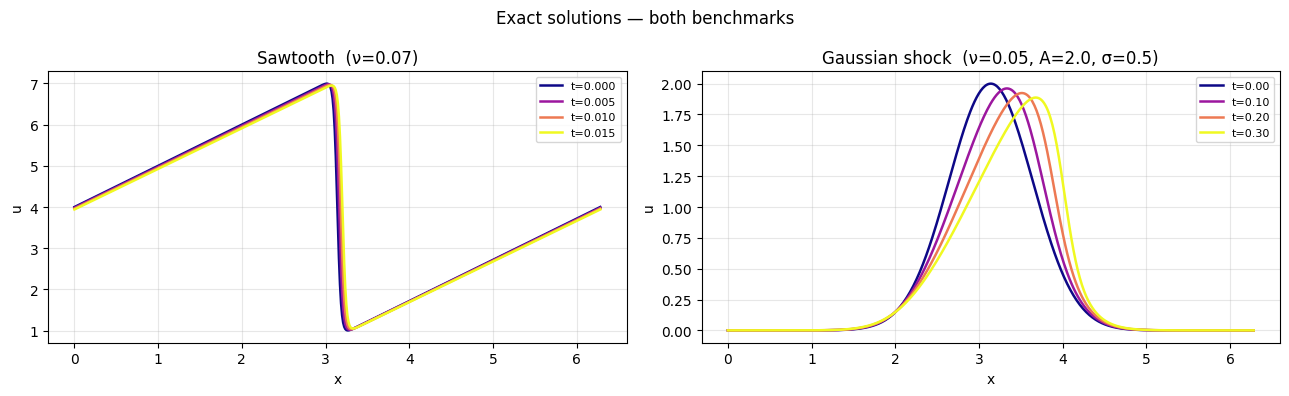

In [3]:
x_plot = np.linspace(X0, XF, 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cmap = plt.cm.plasma

for i, t in enumerate(TIMES_S):
    c = cmap(i / max(len(TIMES_S)-1, 1))
    axes[0].plot(x_plot, hopf_cole(t, x_plot), color=c, lw=1.8, label=f't={t:.3f}')
axes[0].set_title(f'Sawtooth  (ν={NU_S})')
axes[0].set_xlabel('x'); axes[0].set_ylabel('u')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

for i, t in enumerate(TIMES_G):
    c = cmap(i / max(len(TIMES_G)-1, 1))
    axes[1].plot(x_plot, gaussian_exact(t, x_plot), color=c, lw=1.8, label=f't={t:.2f}')
axes[1].set_title(f'Gaussian shock  (ν={NU_G}, A={A_G}, σ={SIGMA_G})')
axes[1].set_xlabel('x'); axes[1].set_ylabel('u')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

fig.suptitle('Exact solutions — both benchmarks', fontsize=12)
plt.tight_layout(); plt.show()

## 2. Initial and Boundary Conditions

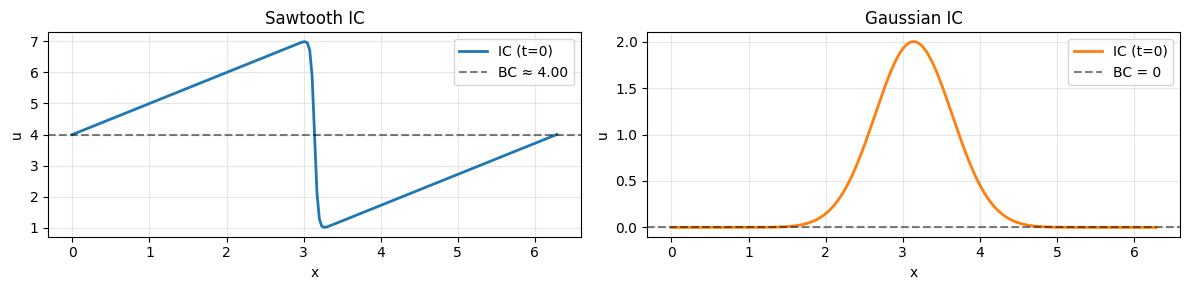

In [4]:
# ── Sawtooth IC / BC ───────────────────────────────────────────────────────────
x_ic_s_np = np.linspace(X0, XF, 201)
u_ic_s_np = hopf_cole(0, x_ic_s_np)

x_ic_s = torch.tensor(x_ic_s_np, dtype=torch.float32).unsqueeze(1)
u_ic_s = torch.tensor(u_ic_s_np, dtype=torch.float32).unsqueeze(1)

u_bc_s_val = float(hopf_cole(0, X0))
x_bc_s = torch.tensor([[X0], [XF]], dtype=torch.float32)
u_bc_s = torch.full((2, 1), u_bc_s_val)

# ── Gaussian IC / BC ──────────────────────────────────────────────────────────
x_ic_g_np = np.linspace(X0, XF, 201)
u_ic_g_np = gaussian_exact(0, x_ic_g_np)

x_ic_g = torch.tensor(x_ic_g_np, dtype=torch.float32).unsqueeze(1)
u_ic_g = torch.tensor(u_ic_g_np, dtype=torch.float32).unsqueeze(1)

# Gaussian decays to ~0 at x=0 and x=2π
x_bc_g = torch.tensor([[X0], [XF]], dtype=torch.float32)
u_bc_g = torch.zeros(2, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(x_ic_s_np, u_ic_s_np, lw=2, label='IC (t=0)')
axes[0].axhline(u_bc_s_val, color='k', ls='--', alpha=0.5, label=f'BC ≈ {u_bc_s_val:.2f}')
axes[0].set_title('Sawtooth IC'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(x_ic_g_np, u_ic_g_np, lw=2, color='C1', label='IC (t=0)')
axes[1].axhline(0, color='k', ls='--', alpha=0.5, label='BC = 0')
axes[1].set_title('Gaussian IC'); axes[1].legend(); axes[1].grid(alpha=0.3)

for ax in axes: ax.set_xlabel('x'); ax.set_ylabel('u')
plt.tight_layout(); plt.show()

## 3. Architecture, Residual, Spatial Dimensions

**Architecture:** `MLP (1 → 64 → 64 → 64 → 1)` with `tanh` activations.  Xavier initialization.

**Residual (Backward Euler):**
$$R = \frac{u - u^{n-1}}{\Delta t} + u\,\frac{\partial u}{\partial x} - \nu\,\frac{\partial^2 u}{\partial x^2}$$

The same residual function is used for both strong and weak forms — only the loss aggregation differs.

In [5]:
N_COLLOC = 500
N_TEST   = 20    # Legendre basis functions for weak form

ARCH        = 'MLP'
PARAMS_ARCH = {'layers': (1, 64, 64, 64, 1), 'activation': 'tanh'}

def burgers_residual(u, u_prev, x, dt, nu):
    du_dx  = torch.autograd.grad(u.sum(),     x, create_graph=True)[0]
    du_dxx = torch.autograd.grad(du_dx.sum(), x, create_graph=True)[0]
    return (u - u_prev) / dt + u * du_dx - nu * du_dxx

x_dim_s = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)
x_dim_g = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

print(PINArchitecture(ARCH, PARAMS_ARCH))

MLP(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 4. Loss Functions

In [6]:
loss_strong_s = PINLossFunction([x_dim_s], burgers_residual, form='strong')
loss_weak_s   = PINLossFunction([x_dim_s], burgers_residual, form='weak', n_test=N_TEST)

loss_strong_g = PINLossFunction([x_dim_g], burgers_residual, form='strong')
loss_weak_g   = PINLossFunction([x_dim_g], burgers_residual, form='weak', n_test=N_TEST)

print(loss_strong_s)
print(loss_weak_s)

PINLossFunction(form='strong', dims=['x'])
PINLossFunction(form='weak', dims=['x'], n_test=20, multi_dim_mode='total_degree')


## 5. Training Helper

In [ ]:
def make_trainer(loss_fn, x_dim, dt, epochs=20000, ic_w=15.0, bc_w=5.0, pde_w=1.0, tolerance=1e-5):
    net = PINArchitecture(ARCH, PARAMS_ARCH)
    return PINTrainer(
        net=net, scheme='TD-PINNS', loss_fn=loss_fn,
        spatial_dims=[x_dim], epochs=epochs, dt=dt,
        lr=1e-3, tolerance=tolerance,
        ic_weight=ic_w, bc_weight=bc_w, pde_weight=pde_w,
        collocation_fn=collocation_curvature,
        verbose=True, log_every=1000,
    )

## 6. Training — Sawtooth

Two independent runs on the sawtooth benchmark: strong form first, then weak form.

In [8]:
print('=== Sawtooth — Strong Form ===')
trainer_ss = make_trainer(loss_strong_s, x_dim_s, DT_S)
t0 = time.perf_counter()
nets_ss = trainer_ss.fit(x_ic_s, u_ic_s, x_bc_s, u_bc_s, T=T_S, nu=NU_S)
t_ss = time.perf_counter() - t0
print(f'Wall time: {t_ss:.1f} s')

=== Sawtooth — Strong Form ===
=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] epoch  1000 | loss 5.5159e-01
  [step 0 / IC] epoch  2000 | loss 3.2753e-02
  [step 0 / IC] epoch  3000 | loss 4.1788e-03
  [step 0 / IC] converged at epoch 3862 | loss 9.9878e-04
=== TD-PINNs | step 1/3  (t = 0.005) ===
  [step 1] epoch  1000 | loss 6.1066e+03
  [step 1] epoch  2000 | loss 2.8213e+02
  [step 1] epoch  3000 | loss 4.7241e+01
  [step 1] epoch  4000 | loss 9.0610e+00
  [step 1] epoch  5000 | loss 4.6492e+00
  [step 1] epoch  6000 | loss 3.1514e+00
  [step 1] epoch  7000 | loss 2.7773e+00
  [step 1] epoch  8000 | loss 2.9517e+00
  [step 1] epoch  9000 | loss 2.5825e+00
  [step 1] epoch 10000 | loss 2.4598e+00
  [step 1] epoch 11000 | loss 2.7951e+00
  [step 1] epoch 12000 | loss 2.1797e+00
  [step 1] epoch 13000 | loss 2.7253e+00
  [step 1] epoch 14000 | loss 2.9280e+00
  [step 1] epoch 15000 | loss 2.3019e+00
  [step 1] epoch 16000 | loss 2.5891e+00
  [step 1] epoch 17000 | loss 

In [9]:
print('=== Sawtooth — Weak Form ===')
trainer_sw = make_trainer(loss_weak_s, x_dim_s, DT_S, tolerance=1e-5)
t0 = time.perf_counter()
nets_sw = trainer_sw.fit(x_ic_s, u_ic_s, x_bc_s, u_bc_s, T=T_S, nu=NU_S)
t_sw = time.perf_counter() - t0
print(f'Wall time: {t_sw:.1f} s  (ratio vs strong: {t_sw/t_ss:.2f}x)')

=== Sawtooth — Weak Form ===
=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] epoch  1000 | loss 6.4235e-01
  [step 0 / IC] epoch  2000 | loss 4.4551e-02
  [step 0 / IC] epoch  3000 | loss 4.0033e-03
  [step 0 / IC] epoch  4000 | loss 1.2874e-03
  [step 0 / IC] converged at epoch 4486 | loss 9.9225e-04
=== TD-PINNs | step 1/3  (t = 0.005) ===
  [step 1] epoch  1000 | loss 2.4268e+00
  [step 1] epoch  2000 | loss 1.1601e+00
  [step 1] epoch  3000 | loss 5.5729e-01
  [step 1] epoch  4000 | loss 2.9610e-01
  [step 1] epoch  5000 | loss 1.2380e-01
  [step 1] epoch  6000 | loss 4.5619e-02
  [step 1] epoch  7000 | loss 3.0461e-02
  [step 1] epoch  8000 | loss 4.3811e-02
  [step 1] epoch  9000 | loss 3.8230e-02
  [step 1] epoch 10000 | loss 2.5425e-02
  [step 1] epoch 11000 | loss 2.5319e-02
  [step 1] epoch 12000 | loss 1.5949e-02
  [step 1] epoch 13000 | loss 2.2349e-02
  [step 1] epoch 14000 | loss 2.3176e-02
  [step 1] epoch 15000 | loss 2.3484e-02
  [step 1] epoch 16000 | lo

## 7. Training — Gaussian Shock

In [22]:
print('=== Gaussian — Strong Form ===')
trainer_gs = make_trainer(loss_strong_g, x_dim_g, DT_G, epochs=5000, tolerance=1e-7)
t0 = time.perf_counter()
nets_gs = trainer_gs.fit(x_ic_g, u_ic_g, x_bc_g, u_bc_g, T=T_G, nu=NU_G)
t_gs = time.perf_counter() - t0
print(f'Wall time: {t_gs:.1f} s')

=== Gaussian — Strong Form ===


TypeError: make_trainer() got an unexpected keyword argument 'tolerance'

In [21]:
print('=== Gaussian — Weak Form ===')
trainer_gw = make_trainer(loss_weak_g, x_dim_g, DT_G, epochs=20000)
t0 = time.perf_counter()
nets_gw = trainer_gw.fit(x_ic_g, u_ic_g, x_bc_g, u_bc_g, T=T_G, nu=NU_G)
t_gw = time.perf_counter() - t0
print(f'Wall time: {t_gw:.1f} s  (ratio vs strong: {t_gw/t_gs:.2f}x)')

=== Gaussian — Weak Form ===
=== TD-PINNs | step 0 — initial condition ===
  [step 0 / IC] converged at epoch 682 | loss 9.9548e-04
=== TD-PINNs | step 1/3  (t = 0.1) ===
  [step 1] converged at epoch 111 | loss 7.9018e-04
=== TD-PINNs | step 2/3  (t = 0.2) ===
  [step 2] converged at epoch 16 | loss 6.9906e-04
=== TD-PINNs | step 3/3  (t = 0.3) ===
  [step 3] converged at epoch 16 | loss 6.9683e-04
Wall time: 0.7 s  (ratio vs strong: 0.04x)


## 8. Solution Plots

In [12]:
dev = trainer_ss.device
x_eval_np = np.linspace(X0, XF, 500)
x_eval = torch.tensor(x_eval_np, dtype=torch.float32).unsqueeze(1).to(dev)

def evaluate_nets(nets, x_eval):
    sols = {}
    for k, net in enumerate(nets):
        net.eval()
        with torch.no_grad():
            sols[k] = net(x_eval).cpu().numpy().ravel()
    return sols

sols_ss = evaluate_nets(nets_ss, x_eval)
sols_sw = evaluate_nets(nets_sw, x_eval)
sols_gs = evaluate_nets(nets_gs, x_eval)
sols_gw = evaluate_nets(nets_gw, x_eval)

print('Evaluation done.')

Evaluation done.


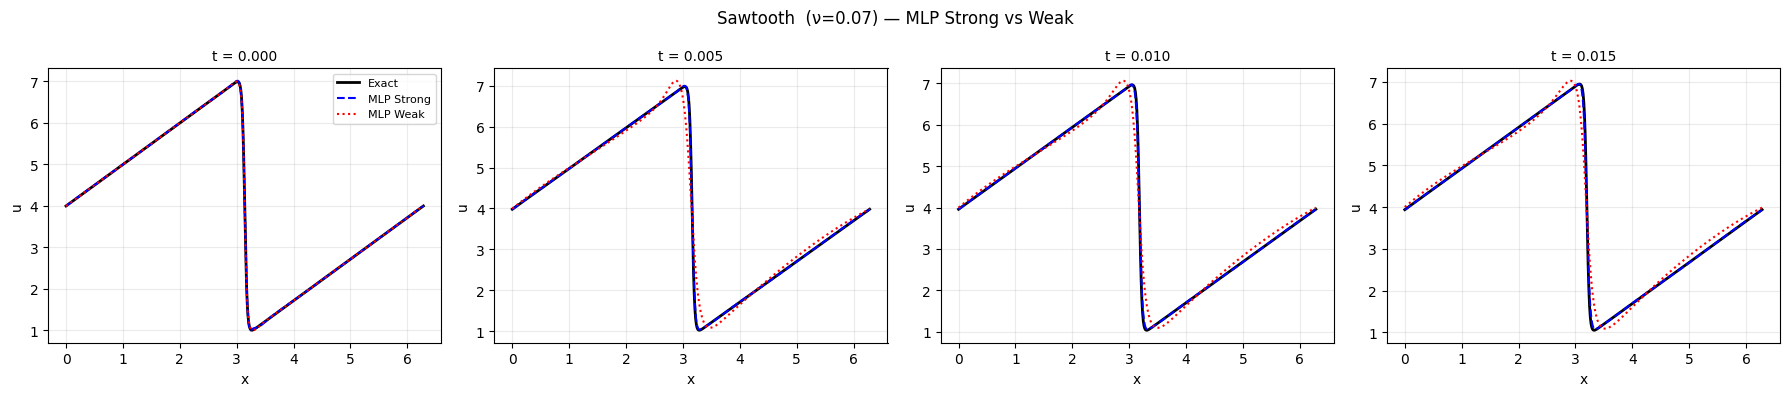

In [13]:
# Sawtooth: one subplot per time step, strong vs weak vs exact
ncols = NT_S + 1
fig, axes = plt.subplots(1, ncols, figsize=(4.5 * ncols, 4))
if ncols == 1: axes = [axes]

for k, t in enumerate(TIMES_S):
    ax = axes[k]
    u_ex = hopf_cole(t, x_eval_np)
    ax.plot(x_eval_np, u_ex,        'k-',  lw=2,   label='Exact')
    ax.plot(x_eval_np, sols_ss[k],  'b--', lw=1.5, label='MLP Strong')
    ax.plot(x_eval_np, sols_sw[k],  'r:',  lw=1.5, label='MLP Weak')
    ax.set_title(f't = {t:.3f}', fontsize=10)
    ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.grid(alpha=0.25)
    if k == 0: ax.legend(fontsize=8)

fig.suptitle(f'Sawtooth  (ν={NU_S}) — MLP Strong vs Weak', fontsize=12)
plt.tight_layout(); plt.show()

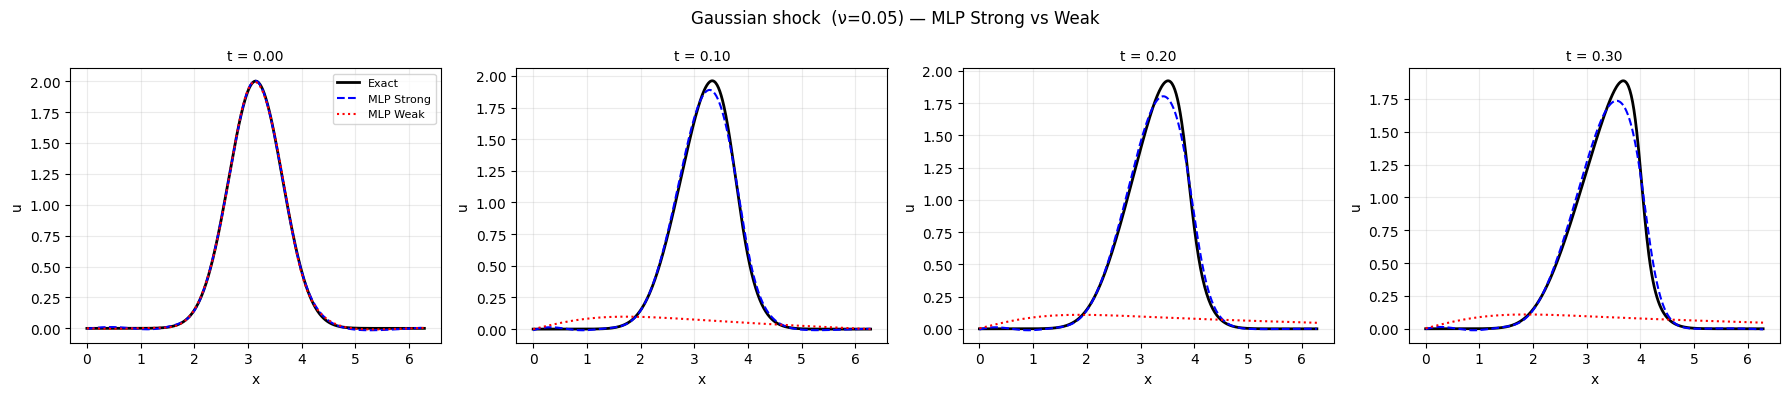

In [14]:
# Gaussian: one subplot per time step
ncols = NT_G + 1
fig, axes = plt.subplots(1, ncols, figsize=(4.5 * ncols, 4))
if ncols == 1: axes = [axes]

for k, t in enumerate(TIMES_G):
    ax = axes[k]
    u_ex = gaussian_exact(t, x_eval_np)
    ax.plot(x_eval_np, u_ex,        'k-',  lw=2,   label='Exact')
    ax.plot(x_eval_np, sols_gs[k],  'b--', lw=1.5, label='MLP Strong')
    ax.plot(x_eval_np, sols_gw[k],  'r:',  lw=1.5, label='MLP Weak')
    ax.set_title(f't = {t:.2f}', fontsize=10)
    ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.grid(alpha=0.25)
    if k == 0: ax.legend(fontsize=8)

fig.suptitle(f'Gaussian shock  (ν={NU_G}) — MLP Strong vs Weak', fontsize=12)
plt.tight_layout(); plt.show()

## 9. Error Analysis — L1, L2, L∞

$$\|e\|_{L^1}=\int|u-u^\star|\,dx,\qquad\|e\|_{L^2}=\sqrt{\int|u-u^\star|^2\,dx},\qquad\|e\|_{L^\infty}=\max_x|u-u^\star|$$

All integrals by the trapezoidal rule on the 500-point evaluation grid.

> **Note on L1 near shocks.** For discontinuous or near-discontinuous solutions, $L^1$ is the most physically meaningful norm — it measures signed-mass error and is insensitive to the exact location of the shock layer.  $L^\infty$ penalises pointwise spikes at the shock heavily.

In [15]:
def all_errors(u_pred, u_exact, x):
    diff = np.abs(u_pred - u_exact)
    L1   = float(_trapz(diff,       x))
    L2   = float(np.sqrt(_trapz(diff**2, x)))
    Linf = float(diff.max())
    denom = float(np.sqrt(_trapz(u_exact**2, x))) + 1e-12
    return {'L1': L1, 'L2': L2, 'Linf': Linf, 'rel_L2': L2 / denom}

def build_error_table(sols_strong, sols_weak, times, exact_fn, label):
    rows = []
    for k, t in enumerate(times):
        u_ex = exact_fn(t, x_eval_np)
        es = all_errors(sols_strong[k], u_ex, x_eval_np)
        ew = all_errors(sols_weak[k],   u_ex, x_eval_np)
        rows.append({
            't': t,
            'strong_L1': es['L1'], 'weak_L1': ew['L1'],
            'strong_L2': es['L2'], 'weak_L2': ew['L2'],
            'strong_Linf': es['Linf'], 'weak_Linf': ew['Linf'],
            'strong_relL2': es['rel_L2'], 'weak_relL2': ew['rel_L2'],
        })
    df = pd.DataFrame(rows).set_index('t')
    print(f'\n=== {label} — per-step errors ===')
    pd.set_option('display.float_format', '{:.5e}'.format)
    print(df.to_string())
    print(f'\n=== {label} — mean over all steps ===')
    for norm in ['L1', 'L2', 'Linf', 'relL2']:
        s = df[f'strong_{norm}'].mean()
        w = df[f'weak_{norm}'].mean()
        print(f'  {norm:7s}  strong={s:.4e}  weak={w:.4e}  ratio(w/s)={w/s:.3f}')
    return df

df_s = build_error_table(sols_ss, sols_sw, TIMES_S, hopf_cole,     'Sawtooth')
df_g = build_error_table(sols_gs, sols_gw, TIMES_G, gaussian_exact, 'Gaussian')


=== Sawtooth — per-step errors ===
              strong_L1     weak_L1   strong_L2     weak_L2  strong_Linf   weak_Linf  strong_relL2  weak_relL2
t                                                                                                             
0.00000e+00 2.89670e-02 2.77216e-02 1.98026e-02 2.29172e-02  4.74084e-02 7.07470e-02   1.80522e-03 2.08915e-03
5.00000e-03 4.74551e-02 7.28882e-01 5.28665e-02 5.90343e-01  1.81487e-01 1.51439e+00   4.82338e-03 5.38612e-02
1.00000e-02 6.10430e-02 8.00317e-01 8.31745e-02 5.76639e-01  2.83159e-01 1.42160e+00   7.59485e-03 5.26542e-02
1.50000e-02 7.14232e-02 8.64426e-01 1.06184e-01 5.78111e-01  3.46595e-01 1.36564e+00   9.70376e-03 5.28316e-02

=== Sawtooth — mean over all steps ===
  L1       strong=5.2222e-02  weak=6.0534e-01  ratio(w/s)=11.592
  L2       strong=6.5507e-02  weak=4.4200e-01  ratio(w/s)=6.747
  Linf     strong=2.1466e-01  weak=1.0931e+00  ratio(w/s)=5.092
  relL2    strong=5.9818e-03  weak=4.0359e-02  ratio(w/s)=6.747



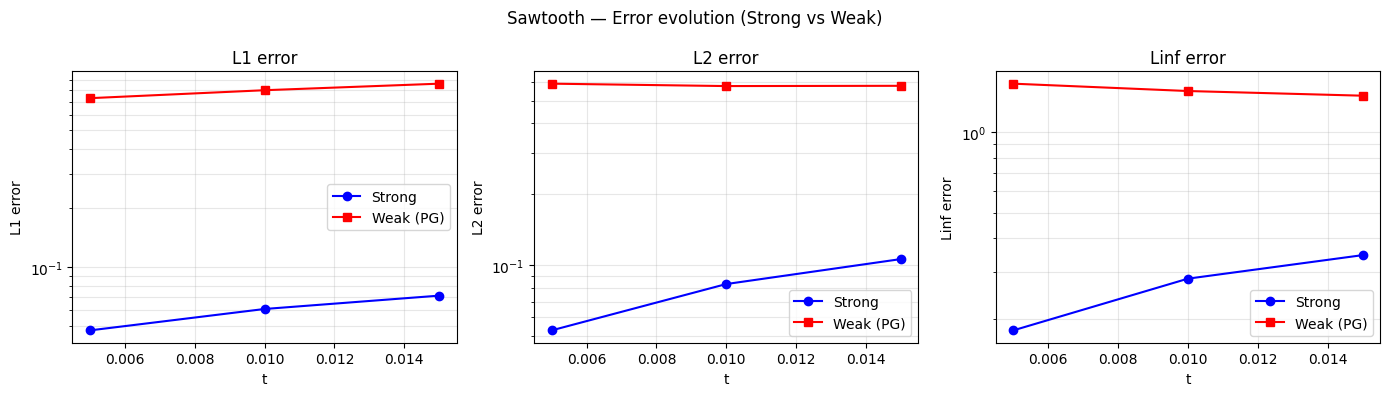

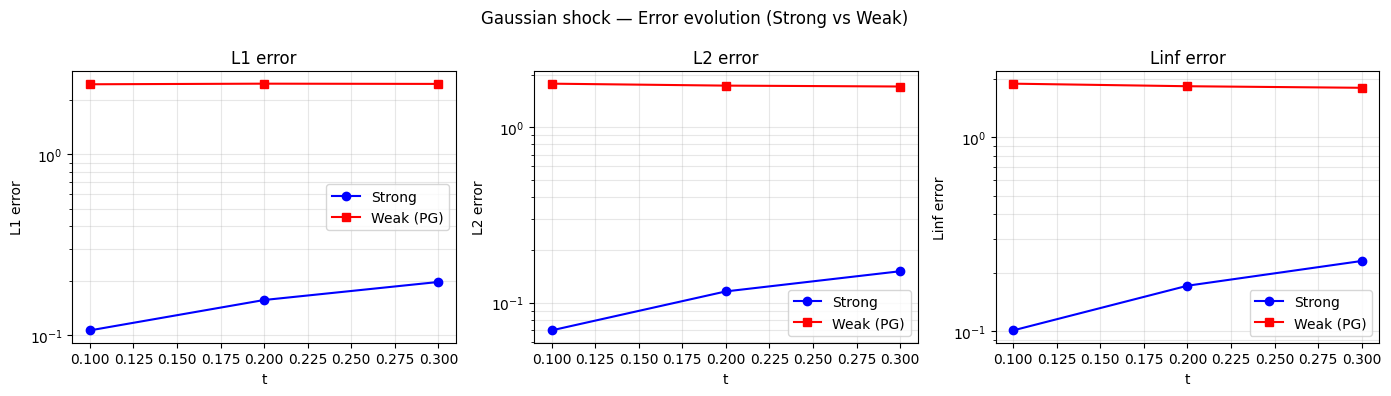

In [16]:
def plot_errors(df, times, title, t0_skip=True):
    t_plot = times[1:] if t0_skip else times  # skip t=0 (IC fit, no PDE error)
    norms  = ['L1', 'L2', 'Linf']
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, norm in zip(axes, norms):
        ax.semilogy(t_plot, df.loc[t_plot, f'strong_{norm}'], 'b-o', ms=6, label='Strong')
        ax.semilogy(t_plot, df.loc[t_plot, f'weak_{norm}'],   'r-s', ms=6, label='Weak (PG)')
        ax.set_xlabel('t'); ax.set_ylabel(f'{norm} error')
        ax.set_title(f'{norm} error'); ax.legend(); ax.grid(True, which='both', alpha=0.3)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

plot_errors(df_s, TIMES_S, 'Sawtooth — Error evolution (Strong vs Weak)')
plot_errors(df_g, TIMES_G, 'Gaussian shock — Error evolution (Strong vs Weak)')

## 10. Conservation Diagnostics

For viscous Burgers with Dirichlet boundary conditions:

$$\frac{d}{dt}\int u\,dx = \nu\,[u_x]_\text{boundary} - \left[\tfrac{u^2}{2}\right]_\text{boundary}$$

Mass is **not** exactly conserved (it depends on the viscous flux at the walls).  Energy dissipates monotonically:

$$\frac{dE}{dt} = -2\nu\int\left(\frac{\partial u}{\partial x}\right)^2\!dx \le 0$$

> **Near discontinuities**, both mass and energy conservation are harder to satisfy with smooth neural networks: the sharp gradients that carry the flux are not well resolved.  The weak form, by integrating the residual against smooth test functions, can partially mitigate this — but an MLP cannot represent the true discontinuity, so some conservation error is expected.

In [17]:
def conservation_data(sols, times, exact_fn):
    mass_pred, energy_pred, mass_ex, energy_ex = [], [], [], []
    for k, t in enumerate(times):
        u_p = sols[k]
        u_e = exact_fn(t, x_eval_np)
        mass_pred.append(_trapz(u_p,    x_eval_np))
        energy_pred.append(_trapz(u_p**2, x_eval_np))
        mass_ex.append(_trapz(u_e,    x_eval_np))
        energy_ex.append(_trapz(u_e**2, x_eval_np))
    return mass_pred, energy_pred, mass_ex, energy_ex

m_ss, e_ss, m_ex_s, e_ex_s = conservation_data(sols_ss, TIMES_S, hopf_cole)
m_sw, e_sw, _,      _      = conservation_data(sols_sw, TIMES_S, hopf_cole)

m_gs, e_gs, m_ex_g, e_ex_g = conservation_data(sols_gs, TIMES_G, gaussian_exact)
m_gw, e_gw, _,      _      = conservation_data(sols_gw, TIMES_G, gaussian_exact)

print('Conservation data computed.')

Conservation data computed.


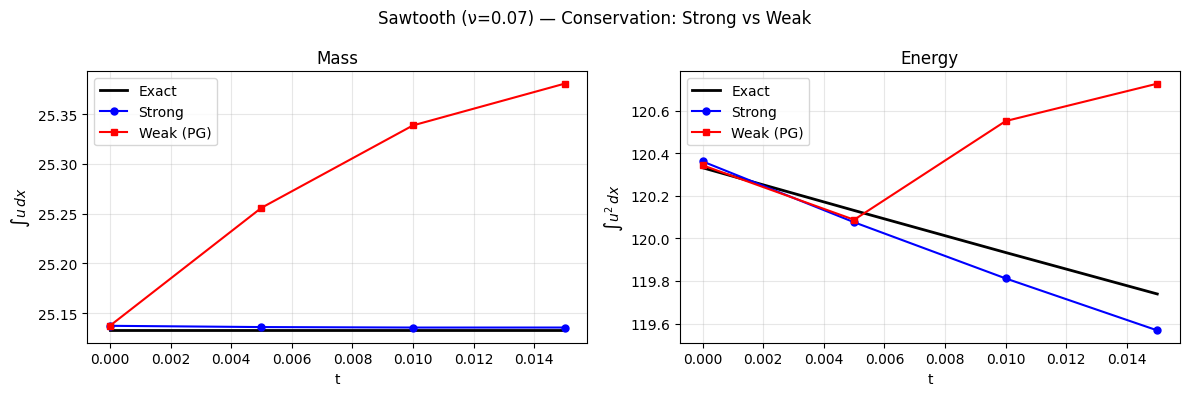

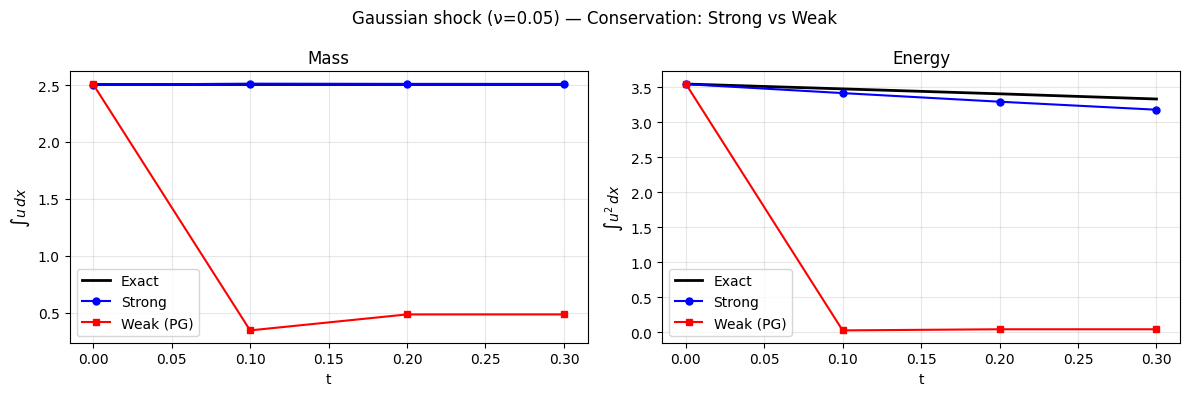

In [18]:
def plot_conservation(times, m_ex, e_ex, m_s, e_s, m_w, e_w, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, vals_ex, vals_s, vals_w, ylabel, label in [
        (axes[0], m_ex, m_s, m_w, r'$\int u\,dx$',   'Mass'),
        (axes[1], e_ex, e_s, e_w, r'$\int u^2\,dx$', 'Energy'),
    ]:
        ax.plot(times, vals_ex, 'k-',  lw=2,   label='Exact')
        ax.plot(times, vals_s,  'b-o', lw=1.5, ms=5, label='Strong')
        ax.plot(times, vals_w,  'r-s', lw=1.5, ms=5, label='Weak (PG)')
        ax.set_xlabel('t'); ax.set_ylabel(ylabel); ax.set_title(label)
        ax.legend(); ax.grid(alpha=0.3)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()

plot_conservation(TIMES_S, m_ex_s, e_ex_s, m_ss, e_ss, m_sw, e_sw,
                  f'Sawtooth (ν={NU_S}) — Conservation: Strong vs Weak')

plot_conservation(TIMES_G, m_ex_g, e_ex_g, m_gs, e_gs, m_gw, e_gw,
                  f'Gaussian shock (ν={NU_G}) — Conservation: Strong vs Weak')

In [19]:
# Conservation error: |pred - exact| for mass and energy
def cons_err_table(times, m_ex, e_ex, m_s, e_s, m_w, e_w, label):
    rows = []
    for i, t in enumerate(times):
        rows.append({
            't': t,
            'strong_Δmass':   abs(m_s[i] - m_ex[i]),
            'weak_Δmass':     abs(m_w[i] - m_ex[i]),
            'strong_Δenergy': abs(e_s[i] - e_ex[i]),
            'weak_Δenergy':   abs(e_w[i] - e_ex[i]),
        })
    df = pd.DataFrame(rows).set_index('t')
    print(f'\n=== {label} — conservation errors |pred − exact| ===')
    print(df.to_string())
    return df

df_cs = cons_err_table(TIMES_S, m_ex_s, e_ex_s, m_ss, e_ss, m_sw, e_sw, 'Sawtooth')
df_cg = cons_err_table(TIMES_G, m_ex_g, e_ex_g, m_gs, e_gs, m_gw, e_gw, 'Gaussian')


=== Sawtooth — conservation errors |pred − exact| ===
             strong_Δmass  weak_Δmass  strong_Δenergy  weak_Δenergy
t                                                                  
0.00000e+00   4.59778e-03 4.61144e-03     2.97223e-02   1.16896e-02
5.00000e-03   3.33318e-03 1.23096e-01     5.55163e-02   4.37602e-02
1.00000e-02   2.85438e-03 2.05863e-01     1.21789e-01   6.18207e-01
1.50000e-02   2.86442e-03 2.47757e-01     1.71211e-01   9.88780e-01

=== Gaussian — conservation errors |pred − exact| ===
             strong_Δmass  weak_Δmass  strong_Δenergy  weak_Δenergy
t                                                                  
0.00000e+00   3.56172e-03 1.84182e-04     1.47127e-03   4.79128e-03
1.00000e-01   5.49319e-03 2.16319e+00     6.01502e-02   3.45026e+00
2.00000e-01   3.57762e-03 2.02292e+00     1.12893e-01   3.36409e+00
3.00000e-01   3.08359e-03 2.02263e+00     1.53006e-01   3.28969e+00


## 11. Summary

### Error comparison (mean over time steps)

| Case | Form | L1 | L2 | L∞ |
|---|---|---|---|---|
| Sawtooth | Strong | `df_s.strong_L1.mean()` | … | … |
| Sawtooth | Weak   | `df_s.weak_L1.mean()`   | … | … |
| Gaussian | Strong | `df_g.strong_L1.mean()` | … | … |
| Gaussian | Weak   | `df_g.weak_L1.mean()`   | … | … |

Run the cell below to fill the table automatically.

In [20]:
summary_rows = []
for case, df, t_ss_, t_sw_, t_gs_, t_gw_ in [
    ('Sawtooth', df_s, t_ss, t_sw, None, None),
    ('Gaussian', df_g, None, None, t_gs, t_gw),
]:
    wall_s = t_ss_ if t_ss_ is not None else t_gs_
    wall_w = t_sw_ if t_sw_ is not None else t_gw_
    for form in ['strong', 'weak']:
        summary_rows.append({
            'Case': case, 'Form': form.capitalize(),
            'L1':   df[f'{form}_L1'].mean(),
            'L2':   df[f'{form}_L2'].mean(),
            'Linf': df[f'{form}_Linf'].mean(),
            'rel_L2': df[f'{form}_relL2'].mean(),
            'wall_s (s)': wall_s if form == 'strong' else wall_w,
        })

df_summary = pd.DataFrame(summary_rows).set_index(['Case', 'Form'])
pd.set_option('display.float_format', '{:.4e}'.format)
print('\n=== Summary Table ===')
print(df_summary.to_string())


=== Summary Table ===
                        L1         L2       Linf     rel_L2  wall_s (s)
Case     Form                                                          
Sawtooth Strong 5.2222e-02 6.5507e-02 2.1466e-01 5.9818e-03  1.2924e+02
         Weak   6.0534e-01 4.4200e-01 1.0931e+00 4.0359e-02  7.0582e+01
Gaussian Strong 1.2482e-01 8.8881e-02 1.2964e-01 4.8248e-02  1.8825e+01
         Weak   1.8425e+00 1.3090e+00 1.3900e+00 7.0946e-01  1.1877e+00
